# Linear Stability Analysis Using Orr-Sommerfeld Equation

> Philipp Schlatter<br>
  philipp.schlatter@fau.de and pschlatt@mech.kth.se <br>
  Institute of Fluid Mechanics (LSTM), Friedrich-Alexander-Universität Erlangen-Nürnberg, Germany <br>
  KTH Engineering Mechanics, Royal Institute of Technology, Stockholm, Sweden <br>
  <br>
  Saleh Rezaeiravesh<br>
  saleh.resaeiravesh@manchester.ac.uk<br>
>  University of Manchester, UK <br> <br>
> This notebook is a part of the [KTH-Nek5000 lecture notes](https://kth-nek5000.github.io/kthNekBook/).


Nbviewer: https://nbviewer.org/github/pschlatt1/notebooks/blob/main/os.ipynb

Binder: https://mybinder.org/v2/gh/pschlatt1/notebooks/main?filepath=os.ipynb

Colab: https://colab.research.google.com/github/pschlatt1/notebooks/blob/main/os.ipynb

In this notebook, we will discuss what one can do with the Orr-Sommerfeld and Squire equations for channel flow (plane Poiseuille flow). 
In particular, we will first perform classical modal stability analysis, by deriving the discretised system matrix followed
by an eigenvalue analysis; we will also plot the neutral curve. Then we will perform non-modal stability analysis, deriving 
transient growth and other interesting things such as numerical abscissa.

All this is done on the example of plane Poiseuille flow (channel flow), but can be adapted easily to other base flows. 
The equations are discretised in space using a Chebyshev collocation method where the boundary conditions are implemented
explicitly for simplicity. The code is written for ease of understanding rather than efficiency, however, the results are all correct and useable.

In [55]:
import sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
  # for Google Colab and interative figures
  !pip install -q ipympl
  from google.colab import output
  output.enable_custom_widget_manager()

In [56]:
%matplotlib widget
# for Binder use instead:
#!pip install scipy
#%matplotlib inline

import sys
import numpy as np
import scipy.linalg as scla
import matplotlib.pyplot as plt
import math as mt
import matplotlib.pylab as pylab
if IN_COLAB:
  !wget -q https://raw.githubusercontent.com/pschlatt1/notebooks/refs/heads/main/chebdif.py
from chebdif import chebdif
if IN_COLAB:
  !wget -q https://raw.githubusercontent.com/pschlatt1/notebooks/refs/heads/main/GLC_pwts.py
from GLC_pwts import GLC_pwts
params = {'legend.fontsize': 10,
          'legend.loc':'best',
          'figure.figsize': (6,4),
          'lines.markerfacecolor':'none',
          'axes.labelsize': 12,
          'axes.titlesize': 12,
          'xtick.labelsize':10,
          'ytick.labelsize':10,
          'grid.alpha':0.6}
pylab.rcParams.update(params)

## 1. Governing equations

### Orr-Sommerfeld equation

In this notebook, the Orr-Sommerfeld equation is numerically solved for the laminar channel flow. The differentiations are approximated by the Chebyshev method which is discussed in a separate notebook. 

The Orr-Sommerfeld equation for linear stability analysis in two dimensions can be derived as, 

$$
\begin{equation}
(U-c)(\hat{v}'' -\alpha^2 \hat{v})-\hat{v} U''=-\frac{i}{\alpha Re}(\hat{v}''''-2\alpha^2 \hat{v}'' +\alpha^4 \hat{v}) \,,
\end{equation}
$$

where $\hat{v}=\hat{v}(y)$, $U(y)$ is the velocity profile, $Re$ denotes Reynolds number, $\alpha$ is the wavenumber, and $c=\omega/\alpha$ is the phase speed for a circular frequency $\omega$. 
All derivatives are with respect to the spatial coordinates $y$ where $y\in[-1,1]$. Using our formulation, the velocity ansatz is

$$
v(x,y,z,t) = \hat{v}(y)\,\exp(i \alpha x + i \beta z)\,\exp(-i \omega t) \, ,
$$

where the temporal exponential can be written with $\lambda = -i \omega$ as

$$
\exp(-i \omega t) = \exp ( \lambda t) \, .
$$

which means that $\omega_i>0$ means growing modes, and $\omega_r$ corresponds to harmonic oscillation.
We can now also consider the three-dimensional case with $\beta\neq0$. Introducing the differentiation operator $D$, where $\hat{v}^{(n)} = D^n \hat{v}$, and the wavenumber $k^2=\alpha^2 + \beta^2$ leads to, 

$$
\underbrace{\left[ -\frac{1}{Re}\left(D^2-k^2 I\right)^2 -i \alpha U'' + i\alpha U (D^2-k^2I)
\right]}_{A_{OS}} \hat{v}
=
\omega\, \underbrace{i (D^2-k^2 I)}_{B_{OS}} \hat{v}
$$

using $\omega=c \alpha$. The system can now be written as, 

$$
A_{OS}\hat{v} = \omega B_{OS}\hat{v} \,.
$$

This equation defines a **generalized eigenvalue problem**. Since $B$ can be inverted, we can also write

$$B_{OS}^{-1} A_{OS} \hat{v} = L_{OS}\hat{v} = \omega \hat{v} = i \sigma \hat{v} \, . $$

### Squire equation

In a similar way, an equation for the wall-normal vorticity $\eta$ can be derived. We obtain for the general 3D case

$$
\underbrace{\left[ -\frac{1}{Re}\left(D^2-k^2 I\right)  + i\alpha U 
\right]}_{A_{SQ}} \hat{\eta}\quad \underbrace{+ i \beta U' }_{C_{SQ}}\hat{v}
=
\omega\, \underbrace{i}_{B_{SQ}} \hat{\eta}  \ .
$$

The Orr-Sommerfeld and Squire equations can be combined in one matrix equation

$$
  \left[ {\begin{array}{cc}
    A_{OS} & 0 \\
    C_{SQ} & A_{SQ} \\
  \end{array} } \right]  
  \cdot 
  \left(
  {\begin{array}{c}
  \hat{v} \\
  \hat{\eta} \\
  \end{array} }
  \right)
 =
  \omega \left[ {\begin{array}{cc}
    B_{OS} & 0 \\
    0 & B_{SQ} \\
  \end{array} } \right]  
  \cdot 
  \left(
  {\begin{array}{c}
  \hat{v} \\
  \hat{\eta} \\
  \end{array} }
  \right)
 $$
 
 or in more compact form:
 
 $$
 A \hat{q} = \omega B \hat{q} 
 $$
 and finally
 $$
 B^{-1} A \hat{q} = L\hat{q} = \omega \hat{q} = i \lambda \hat{q} \, .
 $$
 Alternatively, we can write
 $$ -i L \hat{q} = {L^* \hat{q} = \lambda \hat{q}} $$
 for the eigenvalue $\lambda=-i\omega$ and the matrix $L^* = -i L$.

In the section below, the various matrices are explicitly derived, supplemented with boundary conditions, and the eigenvalue problem is solved.

---

## 2. Discrete temporal stability analysis
For given $Re$, $\alpha$ and $\beta$, the Orr-Sommerfeld equation can be solved for the laminar channel flow with $U(y)=1-y^2$. As a result, the eigenvalues $\omega \in \mathbb{C}$ and associated eigenfunctions $\hat{v}(y)$ are computed. 

**Set the solution parameters:** 
Note that the Reynolds number $Re=Re_\mathrm{cl}$ is based on the centre-line velocity and the channel half-width $h$. The resolution is set by giving the number of collocation points $N$.

In [57]:
Re = 1000    # Re_cl
alpha= 1     # streamwise wavenumber
beta = 0.  # spanwise wavenumber
N = 161      # resolution (number of collocation points)

Some potentially interesting parameters:
- Maximum transient growth: $Re=1000$, $\alpha=0$, $\beta=2.04$ gives $G(t=76)=196$

**Construct the differentiation operators:**
The differential operators are approximated by the Chebyshev collocation method. As described in the Chebyshev notebook, we use a generalized formulation of the Chebyshev differentiation matrix as applied in `chebdif.m`, see [Weideman and Reddy](https://web.iitd.ac.in/~mmehra/MATH4Q03/ft_gateway.cfm.pdf). A Python version of `chebdif.m` which is used here is taken from [dmsuite](https://github.com/ronojoy/pyddx/blob/master/sc/dmsuite.py), but small modifications have been applied. 

In [58]:
k2 = alpha**2 + beta**2
y,D_=chebdif(N,1)
D=D_[0,:,:]
D2=D@D
D4=D2@D2

**Construct the base flow:** Compute the base flow for Poiseuille flow (in this case), together with the first and second derivatives. We set the centre-line velocity $U_{cl}$ and compute the bulk velocity $U_b$ using Clenshaw-Curtis integration.

In [59]:
Ucl = 1
Uvel=np.zeros([N,3])
Uvel[:,0] = Ucl*(1-y**2)
Uvel[:,1] = Ucl*(-2*y)
Uvel[:,2] = Ucl*(-2)

yy,wcc=GLC_pwts(N)

Ubulk = wcc.T@Uvel[:,0]/2
print('Ub / Ucl = {:.5f}'.format(+Ubulk/Ucl))

Ub / Ucl = 0.66667


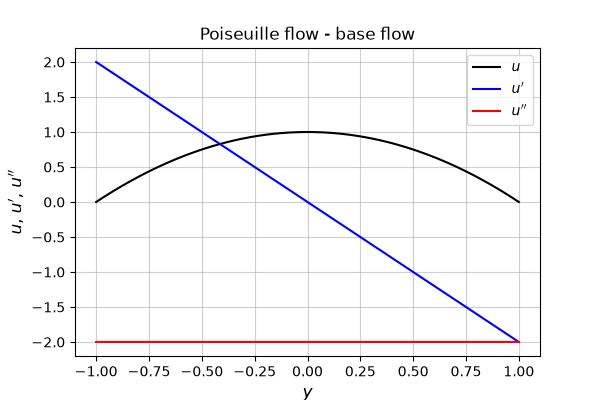

In [60]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.title('Poiseuille flow - base flow')
plt.plot(y,Uvel[:,0],'k',label="$u$")
plt.plot(y,Uvel[:,1],'b',label="$u'$")
plt.plot(y,Uvel[:,2],'r',label="$u''$")
plt.legend(loc='best')
plt.xlabel(r'$y$')
plt.ylabel(r"$u$, $u'$, $u''$")
plt.grid()
plt.show()

**Construct the Orr-Sommerfeld operators A and B**: 

Put together the various matrix components and set the boundary conditions, corresponding to homogeneous Dirichlet conditions on $v$ and $\eta$ (no penetration and no slip conditions on the velocity components), and $Dy=0$ coming from the continuity equation:

$$
\hat{v}(y=\pm 1) =0 \,,\quad\quad \hat{v}'(y=\pm 1) = 0
$$

and

$$
\hat{\eta}(y=\pm 1) =0 \ .
$$

The solution vector is the combination of $\hat{v}$ and $\hat{\eta}$, i.e. $\hat{q} = [\hat{v}\  \hat{\eta}]^T$. Note that we moved the eigenvalues corresponding to the boundary conditions to `Qeig`, typically a large negative imaginary values.

In [61]:
# [ A_OS   0  ] [ vhat ]         [ B_OS  0 ]*[ vhat ] 
# [           ]*[      ] = omega*[         ]*[      ]
# [ C_SQ A_SQ ] [etahat]         [  0   B_SQ]*[etahat]
#
#  A qhat = omega B qhat

I = np.identity(N)
O = np.zeros((N,N))
delta = (D2-I*k2)
delta2 = D4-2*D2*k2+I*k2**2
A_OS = -delta2/Re - 1j*alpha*np.diag(Uvel[:,2]) + 1j*alpha*np.diag(Uvel[:,0])@delta
B_OS = 1j*delta

A_SQ = 1j * alpha*np.diag(Uvel[:,0]) - delta/Re;
B_SQ = 1j * I
C_SQ = 1j * beta*np.diag(Uvel[:,1])   

# move the eigenvalues of the BC to Q
Qeig=-999j

# two homogeneous Dirichlet conditions on v
A_OS[0,:] = Qeig*I[0,:]
B_OS[0,:] = I[0,:]
A_OS[N-1,:] = Qeig*I[-1,:]
B_OS[N-1,:] = I[-1,:]

# two homogeneous Dirichlet conditions on eta
A_SQ[0,:] = Qeig*I[0,:]
B_SQ[0,:] = I[0,:]
A_SQ[N-1,:] = Qeig*I[-1,:]
B_SQ[N-1,:] = I[-1,:]
C_SQ[0,:] = 0.                        
C_SQ[N-1,:] = 0.

# two homogeneous Neumann conditions on v
A_OS[1,:] = Qeig*D[0,:]
B_OS[1,:] = D[0,:]
A_OS[N-2,:] = Qeig*D[-1,:]
B_OS[N-2,:] = D[-1,:]

# compose big matrix
A = np.vstack( (np.hstack((A_OS,O)),np.hstack((C_SQ,A_SQ))))
B = np.vstack( (np.hstack((B_OS,O)),np.hstack((O,B_SQ))))

When the boundary conditions are implemented, both $A$ and $B$ should be full rank (i.e. $2N$):

In [62]:
np.linalg.matrix_rank(A),np.linalg.matrix_rank(B),2*N

(np.int64(322), np.int64(322), 322)

Now we can construct the complete system matrix $L_c$ (denoted `Lc` in the code), and solve the eigenvalue problem. Our formulation is

$$ L_c \hat{q} = \omega_c \hat{q} \quad \text{or} \quad L_c U = U \omega_c \, ,$$

and the eigenvalues are denoted $\omega_c$, and the eigenvectors $U$, respectively. We thus have

$$ L_c = U \omega_c U^{-1} \, .$$

We then sort the eigenvalues/eigenvectors according to the eigenvalues' imaginary part (i.e. the growth rate).

In [63]:
# compute eigenvalues and eigenvectors (A*vhat = omega*B*vhat)
# omega,vv = scla.eig(A,B)

Lc=np.linalg.inv(B) @ A
omegac,U = np.linalg.eig(Lc)

# NOTE: this is the *numerical* conditioning of Lc in the Euclidean norm (dominated by
# the D^4 operator and by the boundary-condition eigenvalues at Qeig). It is NOT a
# measure of non-normality -- for that see the energy-norm condition number in 4.2.
print("2-norm condition number of Lc (numerical conditioning): {:.3e}".format(np.linalg.cond(Lc)))

# sort eigenvalues
isort=np.argsort(-np.imag(omegac))
omegac=omegac[isort]
U=U[:,isort]

# identify high-frequency modes
#for i in range(0,omegac.size):
#    if np.abs(np.real(omegac[i]))>500:
#        omegac[i]=2*Q      

# set the eigenvectors pertaining to the boundary conditions to zero
#for i in range(0,omegac.size):
#    if (np.imag(omegac[i]))<-998:
#        U[:,i]= 0

2-norm condition number of Lc (numerical conditioning): 4.703e+06


---
## 3. Modal stability analysis

Based on the above Orr-Sommerfeld operator, we extract leading eigenvalue and its eigenfunction (TS wave). Each eigenfunction has a specific symmetry which is evaluated and stored in the `prop` arrays

In [64]:
omega_max = -100j
ii=-100

# properties for each eigenvector: 0: sum, 1: zero if symmetric, 2: zero if antisymmetric
propu=np.zeros((3,2*N))
propv=np.zeros((3,2*N))
propw=np.zeros((3,2*N))
prope=np.zeros((3,2*N))
for i in range(0,omegac.size):
    
    v   = U[0:N,i]
    eta = U[N:2*N,i]
    u = (1j/k2)*(alpha*np.dot(D,v) - beta*eta) 
    w = (1j/k2)*(alpha*eta + beta*np.dot(D,v))
    
    propu[0,i]=np.sum(np.abs(u))
    propu[1,i]=np.sum(np.abs(u-u[N-1:None:-1]))
    propu[2,i]=np.sum(np.abs(u+u[N-1:None:-1]))
    propv[0,i]=np.sum(np.abs(v))
    propv[1,i]=np.sum(np.abs(v-v[N-1:None:-1]))
    propv[2,i]=np.sum(np.abs(v+v[N-1:None:-1]))
    propw[0,i]=np.sum(np.abs(w))
    propw[1,i]=np.sum(np.abs(w-w[N-1:None:-1]))
    propw[2,i]=np.sum(np.abs(w+w[N-1:None:-1]))
    prope[0,i]=np.sum(np.abs(eta))
    prope[1,i]=np.sum(np.abs(eta-eta[N-1:None:-1]))
    prope[2,i]=np.sum(np.abs(eta+eta[N-1:None:-1]))
    
    # get the maximum omega_i for phase speeds <0.8
    if np.imag(omegac[i])>np.imag(omega_max):
        if np.real(omegac[i])<0.8*alpha:
            omega_max=omegac[i]
            ii = i

v   = U[0:N,ii]
eta = U[N:2*N,ii]

# use continuity and definition of eta
# u = i/k^2 ( alpha D v - beta * eta)
# w = i/k^2 ( alpha eta + beta D v)

u = (1j/k2)*(alpha*np.dot(D,v) - beta*eta) 
w = (1j/k2)*(alpha*eta + beta*np.dot(D,v))

print('Leading EV omega,c = ',omega_max,omega_max/alpha)

Leading EV omega,c =  (0.3462848600897104-0.04212828817413047j) (0.3462848600897104-0.04212828817413047j)


The structure of the $L_c$ matrix shows that the Orr-Sommerfeld operator is independent from the Squire operator. The latter connects to the OS operator via a diagonal matrix in the lower-left corner. Note that Squire modes are always damped.

/tmp/ipykernel_34914/3599110150.py:1: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig=plt.figure()


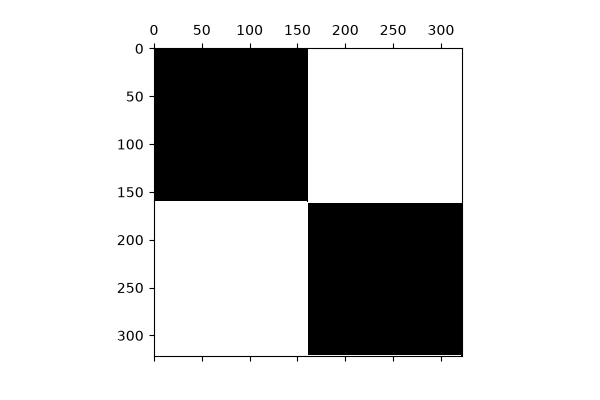

In [65]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.spy(Lc)
plt.show()

We scale and rotate the eigenfunctions such that the maximum of the streamwise velocity is unity (i.e. non-imaginary):

In [66]:
i=np.argmax( abs(u[0:N//2]) )
uscale=u[i]
u[:]   /= uscale
v[:]   /= uscale
w[:]   /= uscale
eta[:] /= uscale

Finally, we can plot the spectrum consisting of the eigenvalues $\omega_c$. The typical Orr-Sommerfeld spectrum appears with the known branches. For Poiseuille flow, the frequency $\omega$ ranges between 0 and $U_{cl} \alpha$ without any symmetry. The bulk velocity appears as a vertical line at $\omega = U_b \alpha$.

We define Squire modes as modes with $\hat{v}=0$ and $\hat{\eta}\ne0$, and Orr-Sommerfeld modes as modes with $\hat{v}\ne0$ (essentially all other modes).

<>:14: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:15: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:14: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:15: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
/tmp/ipykernel_34914/1032357660.py:14: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
  plt.xlabel('$\omega_r$')
/tmp/ipykernel_34914/1032357660.py:15: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is a

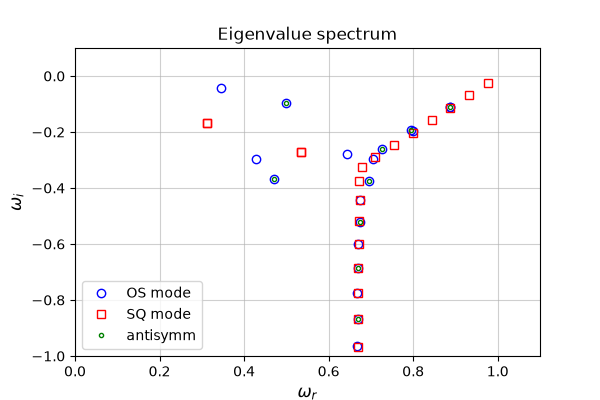

vertical branch omega=0.66667


In [67]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.title('Eigenvalue spectrum')
#plt.plot(omegac.real,omegac.imag,'ob')
i_squire = np.argwhere(np.abs(propv[0,:])<1e-5)
i_nsquire = np.argwhere(np.abs(propv[0,:])>=1e-5)
i_asymm = np.argwhere(np.abs(propv[1,:])>1e-5)
plt.plot(omegac[i_nsquire].real,omegac[i_nsquire].imag,'ob',label='OS mode')
plt.plot(omegac[i_squire].real,omegac[i_squire].imag,'sr',label='SQ mode')
plt.plot(omegac[i_asymm].real,omegac[i_asymm].imag,'.g',label='antisymm')
plt.xlim([0,alpha*1.1])
plt.ylim([-1,0.1])
plt.grid()
plt.xlabel(r'$\omega_r$')
plt.ylabel(r'$\omega_i$')
plt.legend(loc='lower left')
plt.show()
print("vertical branch omega=%.5f" % (Ubulk*alpha))

**Plot amplitude of the perturbations**

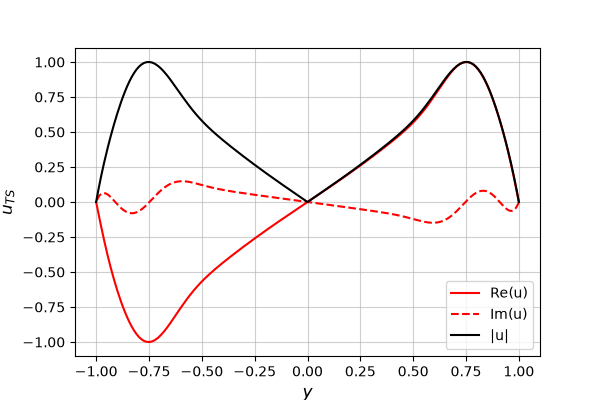

In [68]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.plot(y,u.real,'r',label='Re(u)')
plt.plot(y,u.imag,'r--',label='Im(u)')
plt.plot(y,abs(u),'k-',label='|u|')
plt.legend(loc='best')
plt.xlabel(r'$y$')
plt.ylabel(r'$u_{TS}$')
plt.grid()
plt.show()

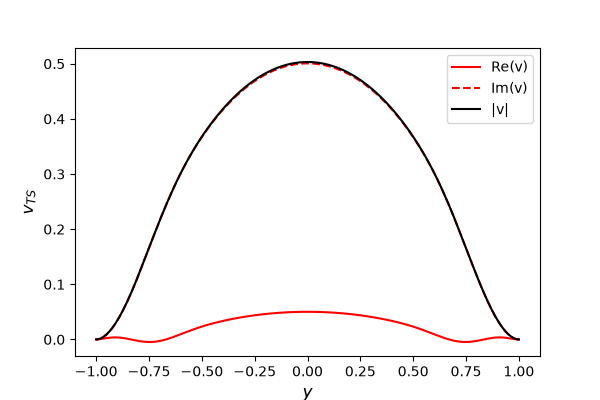

In [69]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.plot(y,v.real,'r',label='Re(v)')
plt.plot(y,v.imag,'r--',label='Im(v)')
plt.plot(y,abs(v),'k-',label='|v|')
plt.xlabel(r'$y$')
plt.ylabel(r'$v_{TS}$')
plt.legend(loc='best')
plt.show()

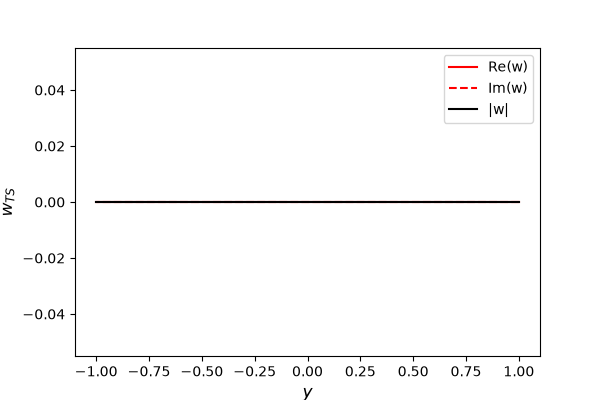

In [70]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.plot(y,w.real,'r',label='Re(w)')
plt.plot(y,w.imag,'r--',label='Im(w)')
plt.plot(y,abs(w),'k-',label='|w|')
plt.xlabel(r'$y$')
plt.ylabel(r'$w_{TS}$')
plt.legend(loc='best')
plt.show()

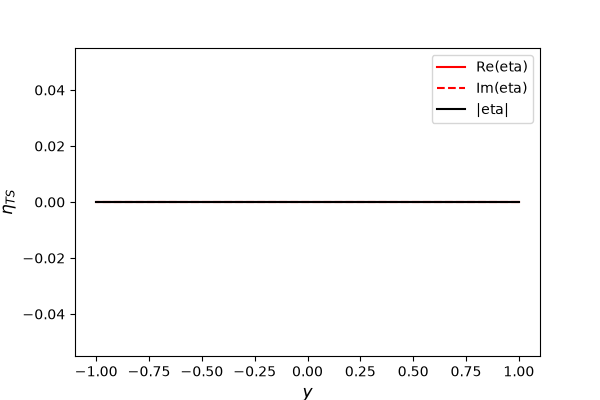

In [71]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.plot(y,eta.real,'r',label='Re(eta)')
plt.plot(y,eta.imag,'r--',label='Im(eta)')
plt.plot(y,abs(eta),'k-',label='|eta|')
plt.xlabel(r'$y$')
plt.ylabel(r'$\eta_{TS}$')
plt.legend(loc='best')
plt.show()

In [72]:
propv[:,ii]    # properties for each eigenvector: 0: sum, 1: zero if symmetric, 2: zero if antisymmetric

array([9.65517795e+00, 2.52109777e-10, 1.93103559e+01])

In [73]:
# file output if needed
if (1==0):
    print('Write output')
    f = open("TS3d_1.txt", "w")
    for i in range(0,N):
        f.write(r"%.15f %.15f %.15f %.15f %.15f %.15f\n" % (u[i].real,u[i].imag,v[i].real,v[i].imag,w[i].real,w[i].imag)) 
    f.close()

---
## 4. Transient growth analysis


We formulate the stability problem as an input-output problem. We use the previously introduced matrix $L$ (or $L^*$)

$$
\frac{\partial \tilde{q}}{\partial t} = - i L \tilde{q} = L^* \tilde{q}
$$

where $\tilde{q} = \tilde{q}(y,t)$. Note that we do not assume normal modes in time as in the previous section 3, where we had a relation between $\tilde{q}$ and $\hat{q}$ as

$$
\tilde{q}(y,t) = \hat{q}(y) e^{-i\omega t} \ ,
$$

which explains why we will consider also non-modal (or non-normal) growth.
The solution can now be written using a matrix exponential

$$
\tilde{q}(t) = \exp (-i L t) \tilde{q}_0 \quad \Rightarrow \quad \tilde{q}(t) = \Phi \tilde{q}_0
$$

with the propagator $\Phi=\exp ( -iLt)$ (we use $\Phi$ rather than $B$ here, since $B$ already denotes the mass matrix of section 2). Using the definition of the matrix exponential,

$$
\exp(X) = \sum_{j=0}^{\infty} \frac{1}{j!} X^j \, ,
$$

we can simplify $\Phi$ with the eigendecomposition of $L=U \omega U^{-1}$ as follows

$$
\Phi= \exp ( -iLt) = \exp ( -i U \omega U^{-1} t ) = U \exp(-i\omega t) U^{-1} \ .
$$

With this, we can define the energy growth $G(t)$ due to the action of $\Phi$ as the square of the induced matrix norm $||\Phi||$:

$$G(t) =\max_{q_0} \frac{||q(t)||^2}{||q_0||^2} = \max_{q_0} \frac{||\Phi q_0||^2}{||q_0||^2} = ||\Phi||^2
$$

The induced norm $||\Phi||$ is the largest singular value $\sigma_1$ of $\Phi$, or equivalently the square root of the largest eigenvalue of $\Phi^H \Phi$; the growth is therefore $G(t)=\sigma_1^2$ (which is what the code computes).

We thus see that the growth of energy is

$$G(t) = || U \exp(-i \omega t) U^{-1}  ||^2 $$

If $U$ and $U^{-1}$ are unitary, i.e. we deal with a normal matrix $L$, then $G(t) = | \exp(-i \omega_\mathrm{max} t)|^2$. In all other cases, for small times, $U$ and $U^{-1}$ may contribute to the norm, and lead to _transient growth_, bounded from above

$$G(t) \le ||U||^2 \, ||U^{-1}||^2 \, | \exp(-i \omega_\mathrm{max} t)|^2 \ . $$

Recall that for an orthogonal (orthonormal) matrix $R^H R = I$. A normal matrix $R^H R = R R^H$ can be diagonalised by unitary matrices.

The level of non-normality can be measured by the condition number of $U$, i.e.

$$\kappa(U)^2 = ||U||^2 \, ||U^{-1}||^2$$

For $\kappa(U)=1$ there is no transient growth, i.e. the system is normal.

**Important:** the norm appearing in $\kappa(U)$ must be *the same norm that defines $G(t)$*, i.e. the energy norm introduced in section 4.1 below, and **not** the Euclidean 2-norm. The energy-norm condition number is computed in section 4.2, once the weight matrix $Q$ is available, and only over the resolved part of the spectrum.

---

### 4.1. Spatial integration weights
We compute the integration weights for the Gauss-Lobatto-Chebyshev points $W$ using the Clenshaw-Curtis weights:

In [74]:
yy,wcc=GLC_pwts(N)
W = np.diag(wcc)

We use the following energy norm 
$$ ||\mathbf{v}||^2 = \frac1{2k^2} \int_{-1}^1 \left( |\mathrm{D} \hat{v}|^2 + k^2 |\hat{v}|^2 + |\hat{\eta}|^2  \right) \mathrm{d} y $$ which can be derived using continuity and the definition of the vorticity (Gustavsson 1986). 

We thus define the corresponding weight matrix $\mathbf{Q}$
(note that $Q$ becomes singular for $k^2=\alpha^2+\beta^2\to 0$, so this formulation cannot be used for the trivial case $\alpha=\beta=0$) which can be used for the discrete evaluation of the energy norm $\hat{q}^T Q \hat{q}$ pertaining to a vector $\hat{q}$. The structure of the weight matrix $Q$ shows a full submatrix in the upper-right corner, and a diagonal matrix in the lower-left corner. 

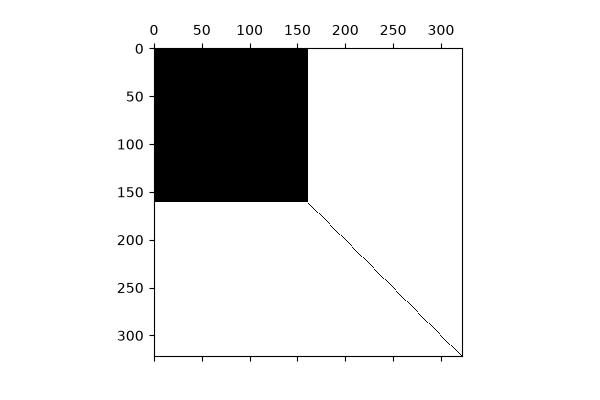

In [75]:
Q=np.vstack( (np.hstack((0.5*D.T @ W @ D/k2 + 0.5*W,O)),
              np.hstack((O,0.5/k2*W))))
fig=plt.figure()
fig.canvas.header_visible = False
plt.spy(Q)
plt.show()

We also compute the "square-root" $Q_\mathrm{sq}$ of $Q=Q_\mathrm{sq}^T Q_\mathrm{sq}$ to multiply a vector $x$ with:

$$ y = Q_\mathrm{sq} x $$

such that the 2-norm of y becomes the same as the $Q$-norm of $x$: 

$$y^T y = (Q_\mathrm{sq} x)^T Q_\mathrm{sq} x = x^T Q_\mathrm{sq}^T Q_\mathrm{sq} x = x^T Q x $$

This factor is used in section 4.2 to evaluate the condition number in the energy norm. This is possible because $Q$ is Hermitian (self-adjoint, check `np.allclose(Q,Q.conj().T)`, so we can actually define a matrix square root.

In [76]:
# Q is Hermitian and positive definite, so eigh is the appropriate (and cheaper) routine
S,V = np.linalg.eigh(Q)
Qsq    = np.diag(np.sqrt(S)) @ V.conj().T
Qsqinv = V @ np.diag(1./np.sqrt(S))
np.allclose(Qsq.conj().T@Qsq,Q)

True

### 4.2. Relevant eigenmodes and non-normality

Before quantifying the non-normality we have to restrict the spectrum. The discrete
problem returns $2N$ eigenvalues, but only the upper part of the spectrum represents
resolved physical modes; the strongly damped end consists of unresolved discretisation
modes (plus the modes carrying the boundary conditions at `Qeig`). We therefore keep the
`nmodes` least damped modes with $\omega_i>-1.5$, denoted $\omega_{rel}$ (`omrel`) with
the corresponding eigenmodes `Urel`.

The level of non-normality is then measured by the condition number of the eigenvector
matrix. The bound quoted in the introduction to section 4,

$$G(t) \le \kappa(U)^2 \, |\exp(-i\omega_\mathrm{max} t)|^2 \ ,$$

only holds if $\kappa(U)$ is the condition number **induced by the energy norm**, i.e.

$$||M||_E = ||Q_\mathrm{sq} M Q_\mathrm{sq}^{-1}||_2 \ , \qquad \kappa_E(U) = ||Q_\mathrm{sq} U||_2 \ ||(Q_\mathrm{sq} U)^{-1}||_2 \ .$$

Three things are easy to get wrong here:

- Using `np.linalg.cond(U)` gives the Euclidean condition number, which is *not* the quantity entering the bound above (and is not even guaranteed to be conservative).
- $\kappa$ is not invariant under a rescaling of the individual eigenvectors, and `np.linalg.eig` returns columns of unit *Euclidean* length. The eigenvectors must therefore be normalised in the energy norm as well, $\hat{q}_j^H Q \hat{q}_j = 1$.
- $\kappa$ must be evaluated over the **resolved** modes only. Taken over all $2N$ discrete modes it is not a converged quantity: it is dominated by the nearly defective pair at the very bottom of the discrete spectrum (here $\omega \approx \pm 17.5 - 1152\,i$ for $N=161$), whose eigenvectors are numerically arbitrary. That value grows with $N$ (roughly $4\cdot 10^2$, $10^3$, $1.4\cdot 10^3$ for $N=161,201,241$) and even changes with the BLAS library, whereas $\kappa_E$ over the retained modes is converged and reproducible ($293$, $299$, $300$ for cut-offs $\omega_i>-1$, $-1.5$, $-2$, independently of $N$).

In [ ]:
# number of modes with omega_i > -1.5 (omegac is sorted by descending imaginary part).
# Note: counting the modes, not the index of the last one -- the latter drops one mode.
nmodes = int(np.sum(np.imag(omegac) > -1.5))

Urel  = U[:,0:nmodes]
omrel = omegac[0:nmodes]

# Normalise the retained eigenvectors to unit energy, q^H Q q = 1. This is a diagonal
# rescaling of Urel, so it leaves G(t), the numerical abscissa, the numerical range and
# the resolvent norm unchanged, but it is required for kappa_E below (and it makes
# cond(F) in section 4.3 equal to kappa_E).
Urel = Urel / np.sqrt(np.real(np.diag(Urel.conj().T @ Q @ Urel)))

print('We use %i eigenmodes out of %i.' % (nmodes,2*N))

# Energy-norm condition number of the (retained) eigenvector matrix = non-normality
kappaE = np.linalg.cond(Qsq @ Urel)
print("kappa_E(Urel) = {:.4e}   <- energy norm, the relevant measure".format(kappaE))
print("kappa_2(Urel) = {:.4e}   <- Euclidean norm, NOT the relevant measure".format(
      np.linalg.cond(Urel)))
print("upper bound for the transient growth: kappa_E^2 = {:.4e}".format(kappaE**2))

# For comparison only: the same quantity over ALL 2N discrete modes. This is NOT a
# converged number (it grows with N and depends on the linear-algebra library) because
# the unresolved modes at the bottom of the spectrum are nearly defective.
Uall = U / np.sqrt(np.real(np.diag(U.conj().T @ Q @ U)))
print("kappa_E over all 2N modes = {:.4e}   <- not converged, do not use".format(
      np.linalg.cond(Qsq @ Uall)))

### 4.3. Reduced system matrix $L$

Based on the retained modes, we now compute the energy-weighted eigenvectors. We first compute the energy of the eigenmodes $E$

In [79]:
E = Urel.conj().T @ Q @ Urel

Factorise $E$ into $E=F^H F$ using SVD, that is $E=V \Sigma V^H$, and $F=\sqrt{\Sigma} V^H$. Note that this is possible because $E=E^H$ is Hermitian. We also compute $F^{-1}=V \sqrt{\Sigma}^{\, -1}$. Note that in `numpy` the third argument is already the Hermitian transpose (as opposed to Matlab).

In [ ]:
Vexp, Sexp, Wexp = np.linalg.svd(E)
F    = np.diag(np.sqrt(Sexp))@Vexp.conj().T
Finv = Vexp@np.diag(1./np.sqrt(Sexp))

# Since the columns of Urel carry unit energy, cond(F) = sqrt(cond(E)) reproduces the
# energy-norm condition number kappa_E of section 4.2.
print("cond(F) = {:.4e}  (= kappa_E = {:.4e})".format(np.linalg.cond(F),kappaE))

Now we have $E=U_r^H Q U_r = F^H F$, such that the $F$ include the (square-root of the) energy weight $Q$. We can build a reduced system $L=F \omega_{rel} F^{-1}$

In [81]:
L=F@np.diag(omrel)@Finv

As expected, this reduced matrix has the same eigenvalues as the original system matrix for the chosen subset of modes, and $F$ are the eigenvectors. 

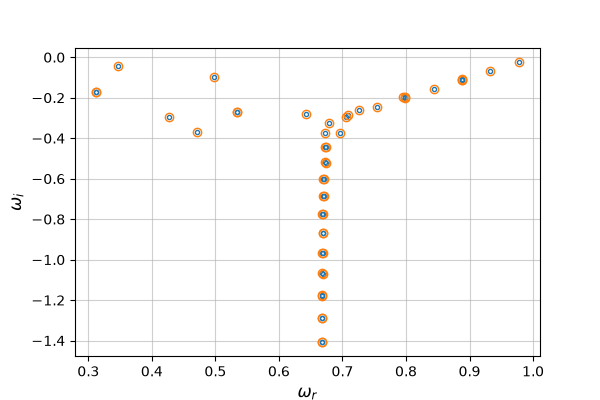

In [83]:
t1,t2=np.linalg.eig(L)

fig=plt.figure()
fig.canvas.header_visible = False
plt.plot(np.real(omrel),np.imag(omrel),'.')
plt.plot(np.real(t1),np.imag(t1),'o')
plt.grid()
plt.xlabel(r'$\omega_r$')
plt.ylabel(r'$\omega_i$')
plt.show()

### 4.4. Transient growth

Now we can evaluate the largest growth at a given time by considering the matrix $\Phi(t) = F \exp ( -i \omega_{rel} t) F^{-1}$. The energy at time $t$ is $(\Phi q_0)^H (\Phi q_0) = q_0^H \Phi^H \Phi q_0$ (without $Q$ as the weights are already included in $F$). To find the largest growth, we need to find the strongest eigenvalue of $\Phi^H \Phi$. This value can be found as the square of the largest singular value of $\Phi$. The corresponding eigenvectors/singular vectors give the initial and final vectors, respectively. In case $\Phi$ is not explicitly available, power iterations with a forward evaluation (corresponding to $\Phi$) followed by an adjoint evaluation (corresponding to $\Phi^H$) is possible.

In [84]:
maxtime = 50
ntime = 101
tvec = np.linspace(0,maxtime,ntime)
q0 = np.zeros((2*N,ntime),dtype=complex)
qmax = np.zeros((2*N,ntime),dtype=complex)
maxgrowth = np.zeros((ntime))

In [85]:
for it in range(0,ntime):
    time=tvec[it]
    uopt,sopt,vopt = np.linalg.svd(F@np.diag(np.exp(-1j*omrel*time))@Finv)
    vopt = vopt.conj().T
    q0[:,it] = Urel@Finv@vopt[:,0]
    qmax[:,it] = Urel@Finv@uopt[:,0]
    maxgrowth[it] = sopt[0]**2
    print("time=%.5f amp=%.5e" % (time,maxgrowth[it]))
it_opt = np.argmax(maxgrowth)
Gmax = maxgrowth[it_opt]
tmax = tvec[it_opt]
print("max growth Gmax=%.5f at t=%.5f" % (Gmax,tmax))

time=0.00000 amp=1.00000e+00
time=0.50000 amp=1.17449e+00
time=1.00000 amp=1.37692e+00
time=1.50000 amp=1.60861e+00
time=2.00000 amp=1.86999e+00
time=2.50000 amp=2.16052e+00
time=3.00000 amp=2.47853e+00
time=3.50000 amp=2.82122e+00
time=4.00000 amp=3.18463e+00
time=4.50000 amp=3.56378e+00
time=5.00000 amp=3.95267e+00
time=5.50000 amp=4.34452e+00
time=6.00000 amp=4.73193e+00
time=6.50000 amp=5.10714e+00
time=7.00000 amp=5.46228e+00
time=7.50000 amp=5.78965e+00
time=8.00000 amp=6.08204e+00
time=8.50000 amp=6.33294e+00
time=9.00000 amp=6.53685e+00
time=9.50000 amp=6.68946e+00
time=10.00000 amp=6.78781e+00
time=10.50000 amp=6.83040e+00
time=11.00000 amp=6.81723e+00
time=11.50000 amp=6.74980e+00
time=12.00000 amp=6.63097e+00
time=12.50000 amp=6.46490e+00
time=13.00000 amp=6.25680e+00
time=13.50000 amp=6.01275e+00
time=14.00000 amp=5.73941e+00
time=14.50000 amp=5.44383e+00
time=15.00000 amp=5.13312e+00
time=15.50000 amp=4.81425e+00
time=16.00000 amp=4.49382e+00
time=16.50000 amp=4.17785e+00


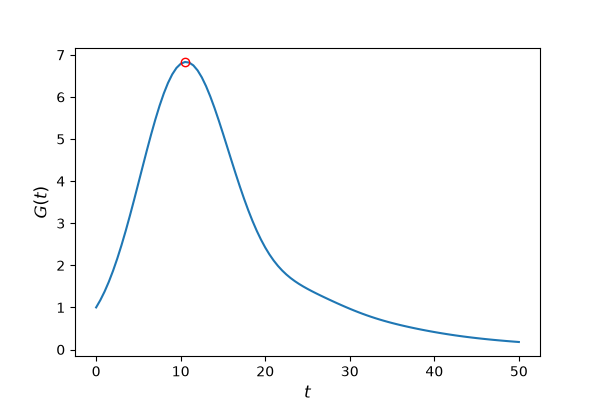

In [86]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.plot(tvec,maxgrowth)
plt.plot(tvec[it_opt],maxgrowth[it_opt],'ro')
plt.xlabel('$t$')
plt.ylabel('$G(t)$')
plt.show()

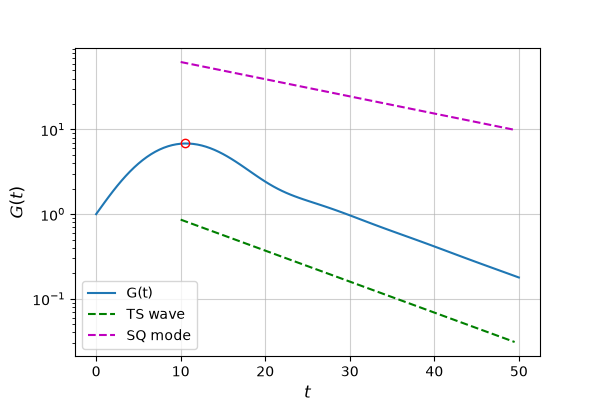

In [87]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.semilogy(tvec,maxgrowth,label='G(t)')
plt.plot(tvec[it_opt],maxgrowth[it_opt],'ro')
plt.plot(tvec[20:-1],2*np.exp(2*tvec[20:-1]*np.imag(omegac[1])),'g--',label='TS wave')
plt.plot(tvec[20:-1],100*np.exp(2*tvec[20:-1]*np.imag(omegac[0])),'m--',label='SQ mode')
plt.xlabel('$t$')
plt.ylabel('$G(t)$')
plt.legend(loc='best')
plt.grid()
plt.show()

In [88]:
tvec[it_opt],maxgrowth[it_opt]

(np.float64(10.5), np.float64(6.8303960913070725))

Some simple checks: $q_0$ and $q_\mathrm{max}$ all have unit energy:

In [89]:
qq=q0[:,it_opt]
qq.conj().T@Q@qq

np.complex128(0.9999999999980912-2.3566218421144924e-15j)

In [90]:
qq=qmax[:,it_opt]
qq.conj().T@Q@qq

np.complex128(1.0000000000000149-6.8833827526759706e-15j)

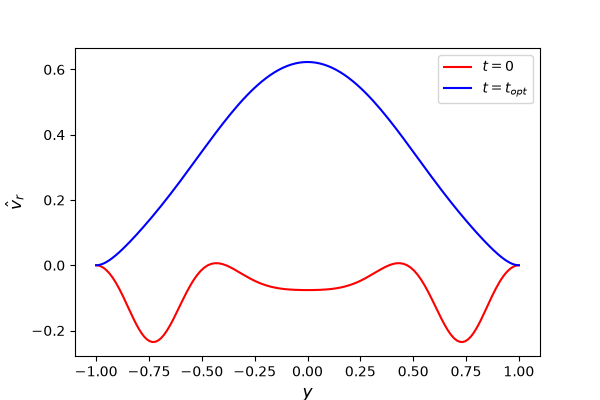

In [92]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.plot(y,np.real(q0[0:N,it_opt]),'r',label='$t=0$')
plt.plot(y,np.real(qmax[0:N,it_opt]),'b',label='$t=t_{opt}$')
plt.xlabel(r'$y$')
plt.ylabel(r'$\hat{v}_r$')
plt.legend()
plt.show()

We can check the computations but considering the original system matrix $L_c$, and computing $q_1 = \exp( -i L_c t) q_0$, and then comparing $G(t)$ with the energy at time $t$ as $E(t)= q_1^T Q q_1$. One can also compare the final vector `qq1`

In [93]:
time=tvec[it_opt]
qq0=q0[:,it_opt]
qq1=scla.expm(-1j*Lc*time)@qq0
(np.abs(qq1.conj().T@Q@qq1),maxgrowth[it_opt])

(np.float64(6.830396091348728), np.float64(6.8303960913070725))

In [94]:
qq1/(qmax[:,it_opt]*np.sqrt(maxgrowth[it_opt]))

/tmp/ipykernel_34914/570044828.py:1: RuntimeWarning: divide by zero encountered in divide
  qq1/(qmax[:,it_opt]*np.sqrt(maxgrowth[it_opt]))
/tmp/ipykernel_34914/570044828.py:1: RuntimeWarning: invalid value encountered in divide
  qq1/(qmax[:,it_opt]*np.sqrt(maxgrowth[it_opt]))


array([0.94959566-3.88137455e-02j, 1.        -4.74159063e-10j,
       1.        -1.44820378e-10j, 1.        -6.18552085e-11j,
       1.        -3.74689649e-11j, 1.        -3.01230190e-11j,
       1.        -2.47074931e-11j, 1.        -2.26370755e-11j,
       1.        -2.20664219e-11j, 1.        -2.05449222e-11j,
       1.        -1.88865130e-11j, 1.        -1.70856733e-11j,
       1.        -1.60922152e-11j, 1.        -1.57745763e-11j,
       1.        -1.52380925e-11j, 1.        -1.51652756e-11j,
       1.        -1.47658902e-11j, 1.        -1.47200158e-11j,
       1.        -1.50374083e-11j, 1.        -1.50172763e-11j,
       1.        -1.51182955e-11j, 1.        -1.54056487e-11j,
       1.        -1.59904295e-11j, 1.        -1.76906151e-11j,
       1.        -1.96930263e-11j, 1.        -2.17878655e-11j,
       1.        -2.25869962e-11j, 1.        -2.26931907e-11j,
       1.        -2.25359850e-11j, 1.        -2.23858617e-11j,
       1.        -2.22855218e-11j, 1.        -2.1770143

The curve $G(t)$ is the envelope of different initial conditions for each time $t$, as can be shown here:

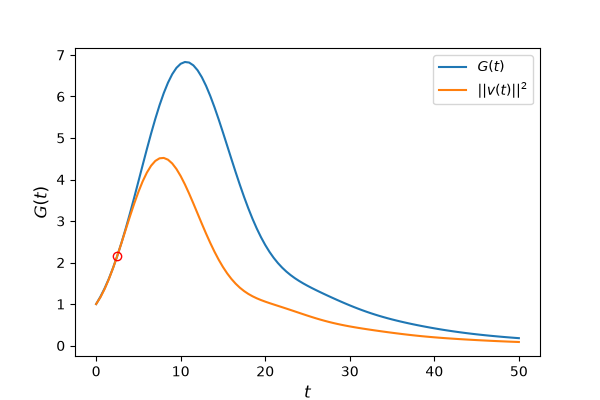

In [95]:
iopt=5
qq0=q0[:,iopt]
en=np.zeros(ntime)
for it in range(0,ntime):
    time=tvec[it]
    qq1=scla.expm(-1j*Lc*time)@qq0
    en[it]=np.real(qq1.conj().T@Q@qq1)
    
fig=plt.figure()
fig.canvas.header_visible = False   
plt.plot(tvec,maxgrowth,label='$G(t)$')
plt.plot(tvec,en,label='$||v(t)||^2$')
plt.plot(tvec[iopt],maxgrowth[iopt],'ro')
plt.xlabel('$t$')
plt.ylabel('$G(t)$')
plt.legend(loc='best')
plt.show()

We can also check that everything we did with the integration weights for the energy were actually correct:

In [96]:
qq0=q0[:,it_opt]          # initial condition
qq0=qmax[:,it_opt]      # outcome at tmax

v   = qq0[0:N]
eta = qq0[N:2*N]
u = (1j/k2)*(alpha*np.dot(D,v) - beta*eta) 
w = (1j/k2)*(alpha*eta + beta*np.dot(D,v))

In [97]:
qq0.conj().T@Q@qq0

np.complex128(1.0000000000000149-6.8833827526759706e-15j)

In [98]:
0.5*(u.conj().T@W@u + v.conj().T@W@v + w.conj().T@W@w)

np.complex128(1.0000000000002796-1.3877787807814457e-17j)

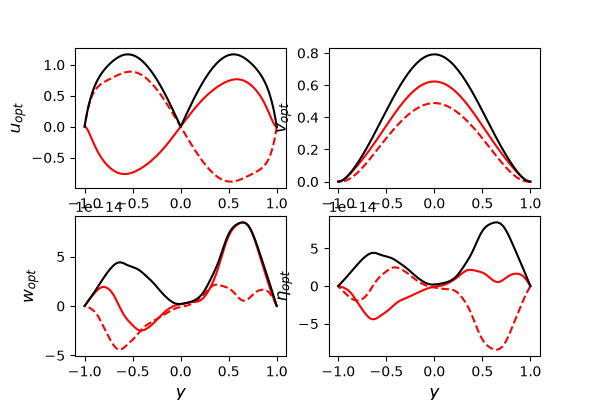

In [100]:
fig, axs = plt.subplots(2, 2)
fig.canvas.header_visible = False
axs[0,0].plot(y,u.real,'r',label='Re(u)')
axs[0,0].plot(y,u.imag,'r--',label='Im(u)')
axs[0,0].plot(y,abs(u),'k-',label='|u|')
axs[0,0].set(xlabel='$y$',ylabel='$u_{opt}$')

axs[0,1].plot(y,v.real,'r',label='Re(u)')
axs[0,1].plot(y,v.imag,'r--',label='Im(u)')
axs[0,1].plot(y,abs(v),'k-',label='|u|')
axs[0,1].set(xlabel='$y$',ylabel='$v_{opt}$')

axs[1,0].plot(y,w.real,'r',label='Re(u)')
axs[1,0].plot(y,w.imag,'r--',label='Im(u)')
axs[1,0].plot(y,abs(w),'k-',label='|u|')
axs[1,0].set(xlabel='$y$',ylabel='$w_{opt}$')

axs[1,1].plot(y,eta.real,'r',label='Re(u)')
axs[1,1].plot(y,eta.imag,'r--',label='Im(u)')
axs[1,1].plot(y,abs(eta),'k-',label='|u|')
axs[1,1].set(xlabel='$y$',ylabel=r'$\eta_{opt}$')

plt.show()

### 4.5. Numerical abscissa

We use now the reduced system matrix $L$ based on the reduced number of eigenvalues, weighted by the energy norm. Now, we compute the quantity $\lambda_0$ as the principal (real) eigenvalue of $L+L^H$ (note that the *numerical abscissa* is more commonly defined as $\lambda_\mathrm{max}\left((L+L^H)/2\right)=\lambda_0/2$, which is the growth rate of the amplitude rather than of the energy; the neutral contour $\lambda_0=0$ is of course the same). The value corresponds to the slope of the energy growth $\partial G(t)/\partial t$ at time $t=0$, which can be obtained via a Taylor expansion.

In [101]:
lam,vv = np.linalg.eig( ( (-1j*L)+(-1j*L).conj().T) )
# Since L+L^H is Hermitian, the eigenvalues are purely real
lam = np.real(lam)
#vv = np.real(vv)
# sort eigenvalues
isort=np.argsort(-lam)
lam=lam[isort]
vv=vv[:,isort]

The numerical abscissa $\lambda_0$ corresponds to the slope of $G(t)$ at $t=0$ (note that the accuracy of the finite-difference approximation may be quite bad, so to get better results one has to decrease the time step in the optimal computation).

In [102]:
(maxgrowth[1]-maxgrowth[0])/(tvec[1]-tvec[0]), lam[0]

(np.float64(0.3489764553917518), np.float64(0.3222810289101992))

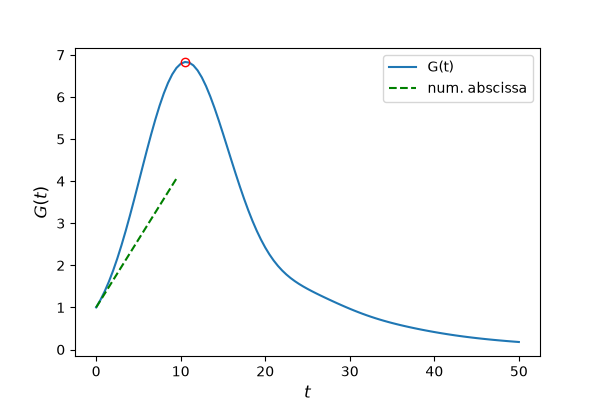

In [103]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.plot(tvec,maxgrowth,label='G(t)')
plt.plot(tvec[it_opt],maxgrowth[it_opt],'ro')
plt.plot(tvec[0:20],1+lam[0]*tvec[0:20],'g--',label='num. abscissa')
plt.xlabel('$t$')
plt.ylabel('$G(t)$')
plt.legend(loc='best')
plt.show()

### 4.6. Numerical range

The numerical range is the generalisation of the numerical abscissa, and corresponds to the maximum amplification due to the matrix $L$.

In [104]:
Ntheta = 100
theta = np.linspace(0, 2*np.pi, Ntheta, endpoint=True)
numrang = np.zeros(Ntheta,dtype=complex)
for ii in range(0,Ntheta):
    M = np.exp(1j*theta[ii])*(-1j*L)
    Mhat = (M+M.conj().T)
    t1,t2 = np.linalg.eig(Mhat)
    t1=np.real(t1)
    i_loc = np.argmax(t1)          # local index -- do not shadow it_opt
    t1m = t1[i_loc]
    t2m = t2[:,i_loc]
    numrang[ii]=(t2m.conj().T@(-1j*L)@t2m)/(t2m.conj().T@t2m)
numrang = -np.imag(numrang)+1j*np.real(numrang)

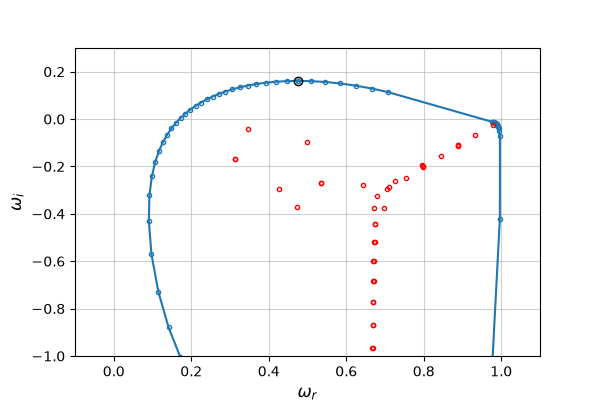

In [106]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.plot(np.real(numrang),np.imag(numrang),'.-')
plt.plot(np.real(omrel),np.imag(omrel),'r.')
plt.plot(np.real(numrang[0]),np.imag(numrang[0]),'ko')
plt.xlim([-0.1,alpha*1.1])
plt.ylim([-1,0.3])
plt.grid()
plt.xlabel(r'$\omega_r$')
plt.ylabel(r'$\omega_i$')
plt.show()

The connection between the numerical range and the numerical abscissa is that the largest imaginary values of the numerical range corresponds to the numerical abscissa $\lambda_0 / 2$.

In [107]:
np.imag(numrang[0])*2, lam[0]

(np.float64(0.32228102891019944), np.float64(0.3222810289101992))

### 4.7. Resolvent norm and pseudospectra

Assume a forced system,

$$\frac{\partial q}{\partial t} = L q + f$$

with a harmonic forcing $f=\hat{f} \exp (-i \omega t)$ (the same sign convention as everywhere else in this notebook). We can then find the particular solution as

$$\hat{q}_p = (-i \omega - L)^{-1} \hat{f} = R(\omega) \hat{f} \ ,$$

which defines the resolvent operator. Its norm is particularly relevant,

$$ R_N(\omega) = || (-i\omega -L )^{-1} || \ , $$

as it describes the potential growth of energy due to the forcing.

Using the Orr-Sommerfeld system with the particular energy norm, we get

$$R_N(\omega) = || F (\omega_{rel} - \omega)^{-1} F^{-1} || \ ,$$

with the eigenvalues $\omega_{rel}$ of the reduced system  $L=F \omega_{rel} F^{-1}$.





In [108]:
N_om = 50
OMr,OMi = np.meshgrid(np.linspace(-0.2,1.2,N_om),np.linspace(-1,0.5,N_om))
resnorm=np.zeros((N_om,N_om))
resnorm0=np.zeros(N_om)

for ii in range(N_om):
    for jj in range(N_om):
        omc = OMr[jj,ii] + 1j*OMi[jj,ii]
        resd = 1./(omrel-omc)
        resnorm[jj,ii]=np.linalg.norm(F@np.diag(resd)@Finv,ord=2)      
        
for ii in range(N_om):    
    omc=OMr[0,ii]
    resd = 1./(omrel-omc)
    resnorm0[ii]=np.linalg.norm(F@np.diag(resd)@Finv,ord=2)

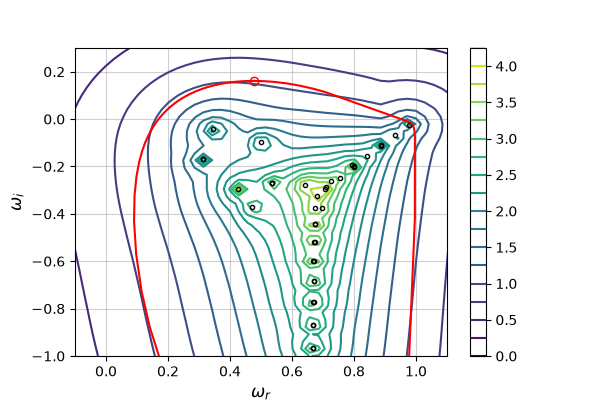

In [110]:
fig=plt.figure()
fig.canvas.header_visible = False
CS=plt.contour(OMr[0,:],OMi[:,0],np.log10(resnorm),levels=15)
plt.colorbar()
plt.plot(np.real(omrel),np.imag(omrel),'k.')
plt.plot(np.real(numrang),np.imag(numrang),'r-')
plt.plot(np.real(numrang[0]),np.imag(numrang[0]),'ro')
plt.xlim([-0.1,alpha*1.1])
plt.ylim([-1,0.3])
plt.grid()
plt.xlabel(r'$\omega_r$')
plt.ylabel(r'$\omega_i$')
#plt.colorbar()
plt.show()

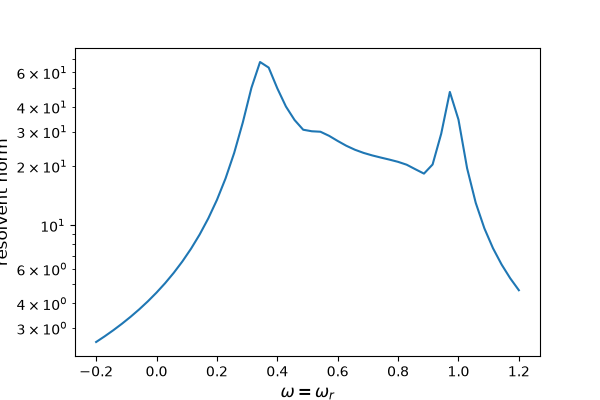

In [112]:
fig=plt.figure()
fig.canvas.header_visible = False
plt.semilogy(OMr[0,:],resnorm0)
plt.xlabel(r'$\omega = \omega_r$')
plt.ylabel('resolvent norm')
plt.show()

Now we plot the $\varepsilon$-pseudospectrum, which is defined as the minimum singular value of $A-z I$ being lower than $\varepsilon$. It turns out that this condition is equivalent to the inverse of the resolvent norm at level $\varepsilon$. The below plot shows colours of the pseudospectrum, with a black contour at $\varepsilon=10^{-3}$:

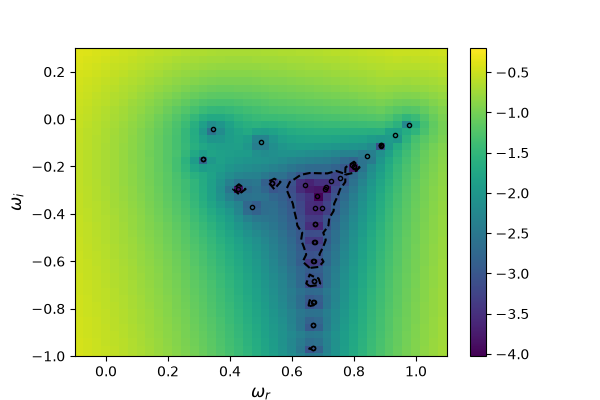

In [113]:
pspec = 1./resnorm
fig=plt.figure()
fig.canvas.header_visible = False
plt.pcolor(OMr[0,:],OMi[:,0],np.log10(pspec),shading='nearest')
plt.colorbar()
plt.contour(OMr[0,:],OMi[:,0],np.log10(pspec),levels=[-3],colors='k')
plt.plot(np.real(omrel),np.imag(omrel),'k.')
plt.xlim([-0.1,alpha*1.1])
plt.ylim([-1,0.3])
#plt.grid()
plt.xlabel(r'$\omega_r$')
plt.ylabel(r'$\omega_i$')
plt.show()

---
## 5. Neutral curves

The aim is to compute the contours of the maximum $imag(c)$ for given ranges of $Re$ and $\alpha$. Of particular interest is the isoline of $max(imag(c))=0$ which specifies the **neutral stability curve**. In what follows we limit ourselves to $\beta=0$ which is well motivated by the Squires theorem saying that 2D waves are most dangerous.

First, we compute $max(imag(c))$ for any $(Re,\alpha)$ in a mesh.

In [114]:
N_Re=21
N_alpha=20
RE,ALPHA = np.meshgrid(np.linspace(1000,40000,N_Re),np.linspace(0.5,1.2,N_alpha))

g1=np.zeros((N_Re,N_alpha))

for ii in range(N_Re):
    for jj in range(N_alpha):
        ReN=RE[jj,ii]
        alphaN=ALPHA[jj,ii]

        delta = (D2-I*alphaN**2)
        delta2 = D4-2*D2*alphaN**2+I*alphaN**4
        AN = -delta2/ReN - 1j*alphaN*np.diag(Uvel[:,2]) + 1j*alphaN*np.diag(Uvel[:,0])@delta
        BN = 1j*delta
        
        Qeig=-999j
        AN[0,:] = Qeig*I[0,:]
        BN[0,:] = I[0,:]
        AN[-1,:]  = Qeig*I[-1,:]
        BN[-1,:] = I[-1,:]
        AN[1,:] = Qeig*D[0,:]
        BN[1,:] = D[0,:]
        AN[-2,:] = Qeig*D[-1,:]
        BN[-2,:] = D[-1,:]
        
        LcN=np.linalg.inv(BN) @ AN
        omegaN,UN = np.linalg.eig(LcN)
        g1[ii,jj]=np.max(omegaN.imag)

and then we plot the contours:

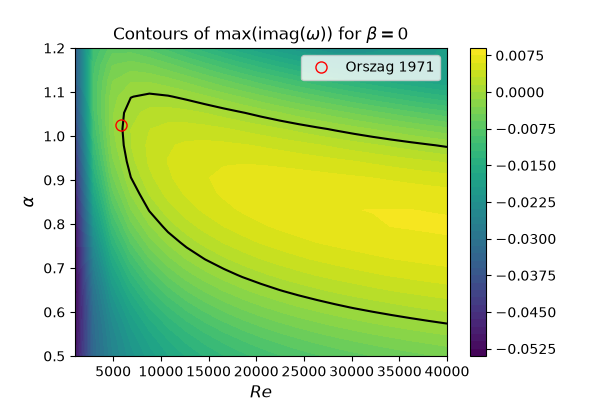

In [115]:
fig=plt.figure()
fig.canvas.header_visible = False
CS=plt.contourf((RE[0,:]),(ALPHA[:,0]),g1.T,levels=40)
plt.colorbar()
CS1=plt.contour((RE[0,:]),(ALPHA[:,0]),g1.T,levels=[0],colors='k')
plt.plot(5772,1.0255,'ro',ms=8,label="Orszag 1971") # Orszag 1971
plt.title(r'Contours of max(imag($\omega$)) for $\beta=0$')
plt.xlabel(r'$Re$')
plt.ylabel(r'$\alpha$')
plt.legend()
plt.show()

Next, we look at the full OS/SQ system to find the critical Reynolds number $Re_g$. This is achieved for $\alpha=0$.

In [116]:
N_Re=25
N_beta=21
RE,BETA = np.meshgrid(np.linspace(10,200,N_Re),np.linspace(0.0,5,N_beta))

g2=np.zeros((N_Re,N_beta))
nmodes = 30

for ii in range(N_Re):
    for jj in range(N_beta):
        ReN=RE[jj,ii]
        betaN=BETA[jj,ii]
        alphaN = 0.001

        k2N = alphaN**2 + betaN**2
        delta = (D2-I*k2N)
        delta2 = D4-2*D2*k2N+I*k2N**2
        
        AOSN = -delta2/ReN - 1j*alphaN*np.diag(Uvel[:,2]) + 1j*alphaN*np.diag(Uvel[:,0])@delta
        BOSN = 1j*delta
        
        ASQN = 1j * alphaN*np.diag(Uvel[:,0]) - delta/ReN;
        BSQN = 1j * I
        CSQN = 1j * betaN*np.diag(Uvel[:,1])  

        Qeig=-999j
        AOSN[0,:] = Qeig*I[0,:]
        BOSN[0,:] = I[0,:]
        AOSN[-1,:]  = Qeig*I[-1,:]
        BOSN[-1,:] = I[-1,:]
        AOSN[1,:] = Qeig*D[0,:]
        BOSN[1,:] = D[0,:]
        AOSN[-2,:] = Qeig*D[-1,:]
        BOSN[-2,:] = D[-1,:]
        
        ASQN[0,:] = Qeig*I[0,:]
        BSQN[0,:] = I[0,:]
        ASQN[-1,:] = Qeig*I[-1,:]
        BSQN[-1,:] = I[-1,:]
        CSQN[0,:] = 0.                        
        CSQN[-1,:] = 0.

        AN = np.vstack( (np.hstack((AOSN,O)),np.hstack((CSQN,ASQN))))
        BN = np.vstack( (np.hstack((BOSN,O)),np.hstack((O,BSQN))))
        QN=np.vstack( (np.hstack((0.5*D.T @ W @ D/k2N + 0.5*W,O)),
              np.hstack((O,0.5/k2N*W))))   
                
        LcN=np.linalg.inv(BN) @ AN
        omegaN,UN = np.linalg.eig(LcN)
        isort=np.argsort(-np.imag(omegaN))
        omegaN=omegaN[isort]
        UN=UN[:,isort]
        UrelN = UN[:,0:nmodes]
        omrelN = omegaN[0:nmodes]
        EN = UrelN.conj().T @ QN @ UrelN
        
        Uexp, Sexp, Vexp = np.linalg.svd(EN)
        FN    = np.diag(np.sqrt(Sexp))@Uexp.conj().T
        FinvN = Uexp@np.diag(1./np.sqrt(Sexp))

        LN=FN@np.diag(omrelN)@FinvN
        
        lamN,vv = np.linalg.eig( ( (-1j*LN)+(-1j*LN).conj().T) )
        lamN = np.real(lamN)
        
        g2[ii,jj]=np.max(lamN)

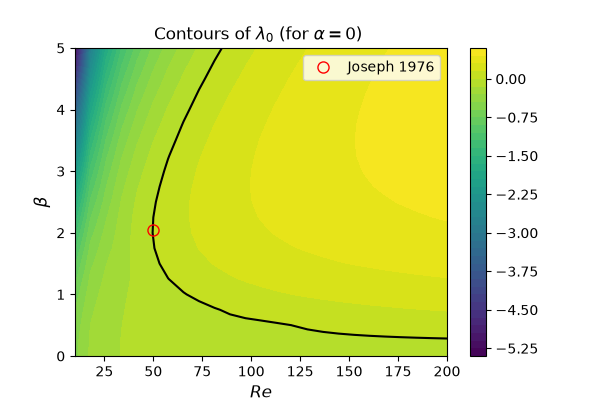

In [117]:
fig=plt.figure()
fig.canvas.header_visible = False
CS=plt.contourf((RE[0,:]),(BETA[:,0]),g2.T,levels=40)
plt.colorbar()
CS1=plt.contour((RE[0,:]),(BETA[:,0]),g2.T,levels=[0],colors='k')
plt.title(r'Contours of $\lambda_0$ (for $\alpha=0$) ')
plt.plot(49.7,2.05,'ro',ms=8,label="Joseph 1976") 
plt.xlabel(r'$Re$')
plt.ylabel(r'$\beta$')
plt.legend()
plt.show()

Finally, let us compute the numerical abscissa for $\beta=0$ as function of $Re$ and $\alpha$. In particular, the zero contour indicates the region in which transient growth may happen. Note that the region of linear instability is also included in the figure.

In [118]:
N_Re=20
N_alpha=21
RE,ALPHA = np.meshgrid(np.logspace(1.7,4,N_Re),np.logspace(-1,0.8,N_alpha))

g2=np.zeros((N_Re,N_alpha))
nmodes = 30

for ii in range(N_Re):
    for jj in range(N_alpha):
        ReN=RE[jj,ii]
        alphaN=ALPHA[jj,ii]
        betaN = 0.0

        k2N = alphaN**2 + betaN**2
        delta = (D2-I*k2N)
        delta2 = D4-2*D2*k2N+I*k2N**2
        
        AOSN = -delta2/ReN - 1j*alphaN*np.diag(Uvel[:,2]) + 1j*alphaN*np.diag(Uvel[:,0])@delta
        BOSN = 1j*delta
        
        ASQN = 1j * alphaN*np.diag(Uvel[:,0]) - delta/ReN;
        BSQN = 1j * I
        CSQN = 1j * betaN*np.diag(Uvel[:,1])  

        Qeig=-999j
        AOSN[0,:] = Qeig*I[0,:]
        BOSN[0,:] = I[0,:]
        AOSN[-1,:]  = Qeig*I[-1,:]
        BOSN[-1,:] = I[-1,:]
        AOSN[1,:] = Qeig*D[0,:]
        BOSN[1,:] = D[0,:]
        AOSN[-2,:] = Qeig*D[-1,:]
        BOSN[-2,:] = D[-1,:]
        
        ASQN[0,:] = Qeig*I[0,:]
        BSQN[0,:] = I[0,:]
        ASQN[-1,:] = Qeig*I[-1,:]
        BSQN[-1,:] = I[-1,:]
        CSQN[0,:] = 0.                        
        CSQN[-1,:] = 0.

        AN = np.vstack( (np.hstack((AOSN,O)),np.hstack((CSQN,ASQN))))
        BN = np.vstack( (np.hstack((BOSN,O)),np.hstack((O,BSQN))))
        QN=np.vstack( (np.hstack((0.5*D.T @ W @ D/k2N + 0.5*W,O)),
              np.hstack((O,0.5/k2N*W))))   
                
        LcN=np.linalg.inv(BN) @ AN
        omegaN,UN = np.linalg.eig(LcN)
        isort=np.argsort(-np.imag(omegaN))
        omegaN=omegaN[isort]
        UN=UN[:,isort]
        UrelN = UN[:,0:nmodes]
        omrelN = omegaN[0:nmodes]
        EN = UrelN.conj().T @ QN @ UrelN
        
        Uexp, Sexp, Vexp = np.linalg.svd(EN)
        FN    = np.diag(np.sqrt(Sexp))@Uexp.conj().T
        FinvN = Uexp@np.diag(1./np.sqrt(Sexp))

        LN=FN@np.diag(omrelN)@FinvN
        
        lamN,vv = np.linalg.eig( ( (-1j*LN)+(-1j*LN).conj().T) )
        lamN = np.real(lamN)
        
        g2[ii,jj]=np.max(lamN)

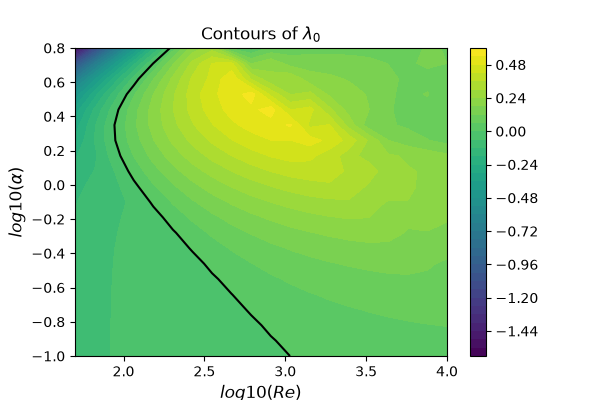

In [120]:
fig=plt.figure()
fig.canvas.header_visible = False
CS=plt.contourf(np.log10(RE[0,:]),np.log10(ALPHA[:,0]),g2.T,levels=40)
plt.colorbar()
CS1=plt.contour(np.log10(RE[0,:]),np.log10(ALPHA[:,0]),g2.T,levels=[0],colors='k')
plt.title(r'Contours of $\lambda_0$')
plt.xlabel(r'$log10(Re)$')
plt.ylabel(r'$log10(\alpha)$')
plt.show()